# Hodgkin–Huxley Action Potential: Spike Peak and Trough under a Constant Stimulus

__Alan L. Hodgkin__ and __Andrew F. Huxley__ (the model, 1952)

__Simen Tennøe__, __Geir Halnes__ and __Gaute T. Einevoll__, University of Oslo and Norwegian University of Life Sciences (the uncertainty study, 2018)

Notebook: P. Constantine with Claude (Anthropic), 2026

<br>

Tennøe, Halnes and Einevoll [[1]](https://doi.org/10.3389/fninf.2018.00049) demonstrate their toolbox Uncertainpy on the original Hodgkin–Huxley model [[2]](https://doi.org/10.1113/jphysiol.1952.sp004764), repeating part of the study of Torres Valderrama et al. [[3]](https://doi.org/10.1186/2190-8567-5-3). Eleven parameters (four initial conditions, three maximum conductances, three reversal potentials and the membrane capacitance) are uniform within ±10 % of their nominal values, a constant current of 140 μA/cm² is injected from $t = 0$, and the membrane potential is studied between 5 and 15 ms with polynomial chaos and first-order Sobol' indices ([[1]](https://doi.org/10.3389/fninf.2018.00049), §4.2, pp. 18–19, and Fig. 4, p. 20). The paper reports the variance of the potential over time but no scalar quantity. We ask which directions in the eleven-dimensional parameter space control the action potential in that window: its peak (value and time), the minimum after it, and the potential at each time, using exact gradients from the forward sensitivity equations at 1000 samples.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import solve_ivp
import active_subspaces as ac
import hh_model as hm

SEED = 2018                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
names = list(hm.NAMES)
labels = [r'$V_0$', r'$C_m$', r'$\bar g_{Na}$', r'$\bar g_K$', r'$\bar g_L$', r'$E_{Na}$', r'$E_K$', r'$E_L$',
          r'$n_0$', r'$m_0$', r'$h_0$']

### Summary

With the paper's eleven inputs, each uniform within ±10 %, and its stimulus of 140 μA/cm², every one of the 1000 samples fires exactly one spike before 5 ms and then an action potential inside the 5–15 ms window. The value of that peak has a one-dimensional active subspace: $\lambda_1/\lambda_2 = 434.4$, and a linear function of $y_1$ has leave-one-out $R^2 = 0.9975$. The direction is mostly the sodium reversal potential $E_{Na}$ (weight $+0.871$) and the maximum sodium conductance $\bar g_{Na}$ ($+0.441$). The time of the peak is also one-dimensional ($\lambda_1/\lambda_2 = 134.5$, quadratic leave-one-out $R^2 = 0.9946$), led by the potassium conductance $\bar g_K$ ($+0.684$), with $E_{Na}$ ($-0.500$), $C_m$ ($+0.353$) and $h_0$ ($+0.287$). The value and time of the minimum after the peak have dominant first eigenvalues ($\lambda_1/\lambda_2 = 49.9$ and $35.3$), and a second active variable raises their quadratic leave-one-out $R^2$ to 0.9988 and 0.9986. Over the window, gradient-based scores single out $\bar g_K$ and $E_{Na}$, as the paper's Sobol' indices do. As in the paper, $V_0$, $m_0$ and $n_0$ have negligible effect, the spread of $V$ is largest at the peak, and the leading input switches between $\bar g_K$ and $E_{Na}$ along the action potential as the paper describes. The mean and standard deviation of $V(t)$ agree with approximate read-offs of the paper's Fig. 4A to within the precision of the read-off. The initial inactivation $h_0$ has a moderate share of the variation up to about 10 ms and a small one after it, both here and in the paper's Fig. 4B; the paper's statement that $h_0$ matters "through most of the simulation" is broader than either.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs normalized to $[-1, 1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows its main trend and a low-dimensional surrogate in $\mathbf y$ can stand in for $f$. The diagonal entry $C_{jj}$ is the mean squared derivative of $f$ along input $j$, a gradient-based measure of the importance of that input.

### The model

The membrane potential $V$ (mV) is measured from rest, with depolarization positive, so that the model "has a resting potential of 0 mV" ([[1]](https://doi.org/10.3389/fninf.2018.00049), Fig. 4 caption, p. 20). With $t$ in ms, conductances in mS/cm², $C_m$ in μF/cm² and the stimulus $I$ in μA/cm²,

$$C_m \frac{dV}{dt} = I - \bar g_{Na} m^3 h (V - E_{Na}) - \bar g_K n^4 (V - E_K) - \bar g_L (V - E_L),$$

$$\frac{dx}{dt} = \alpha_x(V)(1 - x) - \beta_x(V)\,x, \quad x \in \{m, n, h\},$$

$$\alpha_n = \frac{0.01(10 - V)}{e^{(10 - V)/10} - 1},\quad \beta_n = 0.125\,e^{-V/80},\quad
\alpha_m = \frac{0.1(25 - V)}{e^{(25 - V)/10} - 1},\quad \beta_m = 4\,e^{-V/18},\quad
\alpha_h = 0.07\,e^{-V/20},\quad \beta_h = \frac{1}{e^{(30 - V)/10} + 1}.$$

**Sources.** The paper does not print the equations: it names "the original Hodgkin-Huxley model (Hodgkin and Huxley, 1952)" ([[1]](https://doi.org/10.3389/fninf.2018.00049), §4.2, p. 18) and points to the code of the case study in Uncertainpy (p. 19). The rate functions above are those printed in Eq. (1) of Torres Valderrama et al. [[3]](https://doi.org/10.1186/2190-8567-5-3), the study the paper repeats, in the same 0-mV convention. Eq. (1) there does not divide $I$ by $C_m$; we use the Hodgkin–Huxley form above, in which $C_m$ multiplies $dV/dt$. The model here is our own implementation (`hh_model.py`); the Uncertainpy example code [[4]](https://github.com/simetenn/uncertainpy/tree/ffb2400289743066265b9a8561cdf3b72e478a28/examples/valderrama) is GPL-licensed and was not copied.

**Inputs.** The eleven parameters and their nominal values are Table 2 of the paper ([[1]](https://doi.org/10.3389/fninf.2018.00049), p. 19); "each of these parameters has a uniform distribution in the range ±10% around their original value" ([[1]](https://doi.org/10.3389/fninf.2018.00049), §4.2, p. 19). For the two negative nominal values ($V_0$, $E_K$) the lower bound is 1.1 times and the upper bound 0.9 times the nominal value. The upper bound of $h_0$, 1.0998, lies above 1, the largest value a gating variable can have; we keep the paper's stated ranges (see the data checks below).

**Stimulus and window.** $I = 140$ μA/cm², constant from $t = 0$, and the window $5 \le t \le 15$ ms are from the caption of Fig. 4 of the paper ([[1]](https://doi.org/10.3389/fninf.2018.00049), p. 20). The end time 15 ms, the solver (`scipy` DOP853 with relative tolerance $10^{-10}$, absolute $10^{-12}$) and the outputs below are this data set's choices.

**Quantities of interest.** With this stimulus the model fires a first spike at once (at 0.620 ms for the nominal parameters, below) and then a second, smaller action potential inside the window. The paper's Fig. 4 marks "the peak of the first action potential" with a yellow line and "the minimum after the first action potential" with a cyan line (caption, p. 20). The lines sit at about 8.67 and 10.85 ms (our approximate read-off of the figure), inside the window, so the paper's "first action potential" is the first one in the window, not the initial spike. We take as outputs:

- $V_{peak}$, $t_{peak}$: the value and time of the first local maximum of $V$ after 5 ms;
- $V_{min}$, $t_{min}$: the value and time of the first local minimum after it;
- $V(t)$ at $t = 5, 5.5, \ldots, 15$ ms (21 times), for a comparison with the time-resolved results of the paper.

Gradients with respect to the physical inputs come from the forward sensitivity equations solved with the state. At an extremum, $dV/dt = 0$, so $\partial V_{peak}/\partial p_j$ is the sensitivity $s_{V,j}$ at $t_{peak}$, and $\partial t_{peak}/\partial p_j = -(\nabla_x F_V\cdot \mathbf s_j + \partial F_V/\partial p_j)/(\nabla_x F_V\cdot \mathbf F)$ at $t_{peak}$, with $\mathbf F$ the right-hand side and $F_V = dV/dt$.

In [2]:
print(f"{'input':5s} {'units':8s} {'nominal':>9s} {'lower':>10s} {'upper':>10s}")
for j, n in enumerate(names):
    print(f'{n:5s} {hm.UNITS[j]:8s} {hm.NOMINAL[j]:9.5g} {hm.LOWER[j]:10.5g} {hm.UPPER[j]:10.5g}')
print(f'stimulus I = {hm.I_STIM:g} uA/cm^2 from t = 0; solve on [0, {hm.T_END:g}] ms; window {hm.T_WINDOW} ms')

input units      nominal      lower      upper
V0    mV             -10        -11         -9
Cm    uF/cm^2          1        0.9        1.1
gNa   mS/cm^2        120        108        132
gK    mS/cm^2         36       32.4       39.6
gL    mS/cm^2        0.3       0.27       0.33
ENa   mV             112      100.8      123.2
EK    mV             -12      -13.2      -10.8
EL    mV          10.613     9.5517     11.674
n0    -           0.0011    0.00099    0.00121
m0    -           0.0003    0.00027    0.00033
h0    -           0.9998    0.89982     1.0998
stimulus I = 140 uA/cm^2 from t = 0; solve on [0, 15] ms; window (5.0, 15.0) ms


The nominal trajectory shows the first spike, then the action potential inside the window (shaded) with its peak and the minimum after it.

nominal maxima of V (ms, mV): (0.620, 113.96), (8.681, 45.87), (14.971, 34.52)
nominal minima of V (ms, mV): (4.129, 1.99), (10.815, 8.37)
nominal outputs: V_peak 45.869 mV at 8.681 ms; V_min 8.366 mV at 10.815 ms


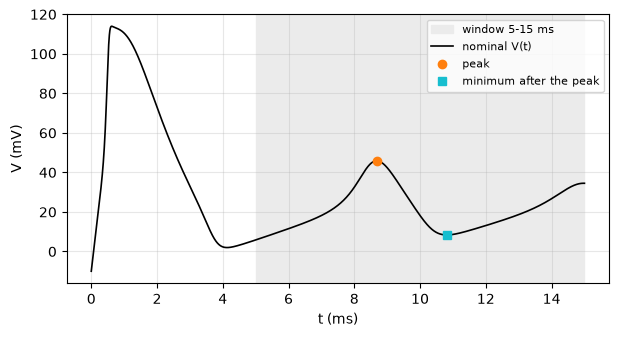

In [3]:
t = np.linspace(0, hm.T_END, 3001)
v_nom = hm.trajectory(hm.NOMINAL, t)
tmax, vmax, tmin_all, vmin_all = hm.extrema(hm.NOMINAL)
f_nom = hm.qoi(hm.NOMINAL)
print('nominal maxima of V (ms, mV):', ', '.join(f'({a:.3f}, {b:.2f})' for a, b in zip(tmax, vmax)))
print('nominal minima of V (ms, mV):', ', '.join(f'({a:.3f}, {b:.2f})' for a, b in zip(tmin_all, vmin_all)))
print(f'nominal outputs: V_peak {f_nom[0]:.3f} mV at {f_nom[1]:.3f} ms; V_min {f_nom[2]:.3f} mV at {f_nom[3]:.3f} ms')
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.axvspan(*hm.T_WINDOW, color='0.92', label='window 5-15 ms')
ax.plot(t, v_nom, 'k', lw=1.2, label='nominal V(t)')
ax.plot(f_nom[1], f_nom[0], 'o', color='tab:orange', label='peak')
ax.plot(f_nom[3], f_nom[2], 's', color='tab:cyan', label='minimum after the peak')
ax.set_xlabel('t (ms)'); ax.set_ylabel('V (mV)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.close(fig)
fig

At the nominal parameters the first spike reaches 113.96 mV at 0.620 ms, and the action potential in the window peaks at 45.87 mV at 8.681 ms, within the interval "between t = 8 and 9 ms" in which the paper places the upstroke and peak ([[1]](https://doi.org/10.3389/fninf.2018.00049), §4.2, p. 19). The minimum after it is 8.37 mV at 10.815 ms. The next maximum, 34.52 mV at 14.971 ms, is the peak of the next action potential, just before the end of the window. It is not one of our outputs; `generate_data.py` finds such a peak before 15 ms in 592 of the 1000 samples. `generate_data.py` also checks that every sample has exactly one maximum before 5 ms, so the peak after 5 ms is the same feature in every sample.

### Load data

`generate_data.py` drew $M = 1000$ independent uniform samples of the eleven inputs (seed 2018) and wrote the physical inputs, the 25 outputs and their gradients with respect to the physical inputs (see `DATA.md`).

In [4]:
X = np.loadtxt('inputs.csv', delimiter=',')                       # (M, 11) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',')                      # (M, 25) outputs
G = np.loadtxt('gradients.csv', delimiter=',').reshape(len(X), hm.N_QOI, hm.M_INPUTS)   # physical gradients
M = len(X)
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}')
inside = np.all((X >= hm.LOWER) & (X <= hm.UPPER))
print(f'all inputs within their bounds: {inside}; distinct rows {len(np.unique(X, axis=0))} of {M}; '
      f'fewest distinct values in a column: {min(len(np.unique(X[:, j])) for j in range(hm.M_INPUTS))}')
U = (X - hm.LOWER) / (hm.UPPER - hm.LOWER)
ks = [stats.kstest(U[:, j], 'uniform') for j in range(hm.M_INPUTS)]
pmin = min(k.pvalue for k in ks)
print('Kolmogorov-Smirnov test against the declared uniform, smallest p-value: '
      f'{pmin:.3f} ({names[int(np.argmin([k.pvalue for k in ks]))]}); '
      f'times the {hm.M_INPUTS} tests (Bonferroni): {min(1.0, hm.M_INPUTS * pmin):.2f}')
print(f"samples with h0 > 1: {int(np.sum(X[:, names.index('h0')] > 1))} of {M}")
for i, (n, u) in enumerate(zip(hm.QOI_NAMES[:4], hm.QOI_UNITS[:4])):
    print(f'{n:6s} range [{F[:, i].min():.3f}, {F[:, i].max():.3f}] {u}, mean {F[:, i].mean():.3f}, std {F[:, i].std(ddof=1):.3f}')

inputs (1000, 11), outputs (1000, 25), gradients (1000, 25, 11)
all inputs within their bounds: True; distinct rows 1000 of 1000; fewest distinct values in a column: 1000


Kolmogorov-Smirnov test against the declared uniform, smallest p-value: 0.018 (ENa); times the 11 tests (Bonferroni): 0.20
samples with h0 > 1: 473 of 1000
vpeak  range [32.123, 59.075] mV, mean 45.965, std 5.550
tpeak  range [8.333, 9.048] ms, mean 8.686, std 0.136
vmin   range [4.187, 14.171] mV, mean 8.489, std 1.714
tmin   range [10.499, 11.220] ms, mean 10.832, std 0.135


We check the files against the model at five samples, and the gradients against central differences (step $10^{-5}$ of each input's range, solves at relative tolerance $10^{-12}$) at three samples, as relative errors of each output's gradient in normalized coordinates.

In [5]:
span = hm.UPPER - hm.LOWER
d_file = max(np.max(np.abs(hm.qoi_and_grad(X[k])[0] - F[k])) for k in range(5))
print(f'largest |model - outputs.csv| at the first 5 samples: {d_file:.1e}')
tight = dict(rtol=1e-12, atol=1e-14)
err = []
for k in range(3):
    h = 1e-5 * span
    Fd = np.column_stack([(hm.qoi(X[k] + h[j] * e, **tight) - hm.qoi(X[k] - h[j] * e, **tight)) / (2 * h[j])
                          for j, e in enumerate(np.eye(hm.M_INPUTS))])
    Gn, Fn = G[k] * span / 2, Fd * span / 2
    err.append(np.linalg.norm(Gn - Fn, axis=1) / np.linalg.norm(Gn, axis=1))
err = np.array(err)
print('gradients vs central differences, largest relative error: '
      + ', '.join(f'{n} {err[:, i].max():.1e}' for i, n in enumerate(hm.QOI_NAMES[:4]))
      + f', V(t) {err[:, 4:].max():.1e}')

largest |model - outputs.csv| at the first 5 samples: 5.0e-12


gradients vs central differences, largest relative error: vpeak 1.7e-09, tpeak 6.3e-09, vmin 3.2e-09, tmin 2.5e-08, V(t) 4.5e-07


All inputs lie within their bounds, the 1000 rows are distinct, and no input is discrete (every column has 1000 distinct values). The smallest Kolmogorov–Smirnov p-value against the declared uniform distributions, 0.018 for $E_{Na}$, is unremarkable among eleven tests (0.20 after the Bonferroni correction). 473 samples have $h_0 > 1$, above the largest value of a gating variable: the paper's ±10 % range around 0.9998 reaches 1.0998. We keep the paper's range. The equations stay well defined: $h$ relaxes toward $h_\infty(V) < 1$, and $h_0$ has a modest effect on the outputs (below). No logarithms are taken. The files agree with the model to within a few times $10^{-12}$, and the gradients agree with central differences to a relative error below $10^{-6}$ (`check_accuracy.py` repeats this check at ten samples).

### The membrane potential over the window

To compare with Fig. 4A of the paper, whose features are narrower than the 0.5 ms spacing of the output times, we recompute $V(t)$ for all 1000 samples on a 0.01 ms grid. The 1000 systems are independent, so one call of the same solver, at the same tolerances, integrates them together; at the 21 output times the result is checked against `outputs.csv`. As in Fig. 4A, the figure shows the sample mean of $V(t)$ with the 90 % interval (5th to 95th percentile) on the left axis and the standard deviation on the right axis.

0.01 ms grid against outputs.csv at the 21 output times: largest |difference| 4.5e-08 mV
local maxima of the standard deviation (ms, mV): (8.45, 6.10), (10.15, 2.61), (14.64, 5.01)
local maxima of the mean (ms, mV): (8.66, 45.31), (14.89, 34.13); local minima: (10.84, 8.65)
mean 33.99 mV and standard deviation 4.49 mV at 15 ms; standard deviation up to 7.5 ms at most 1.54 mV


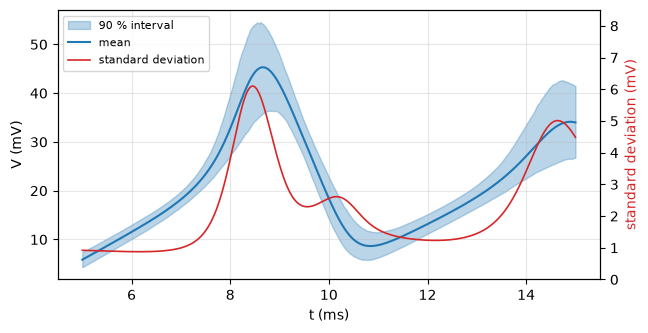

In [6]:
t_fine = np.linspace(*hm.T_WINDOW, 1001)                          # 0.01 ms apart
P = X.T                                                           # (11, M): every sample at once
x0 = np.array([P[names.index(n)] for n in ('V0', 'm0', 'n0', 'h0')])   # (v, m, n, h) at t = 0
sol = solve_ivp(lambda t, y: hm.rhs(y.reshape(4, M), P).ravel(), (0.0, hm.T_END), x0.ravel(),
                method='DOP853', t_eval=t_fine, rtol=hm.RTOL, atol=hm.ATOL)
Vf = sol.y.reshape(4, M, -1)[0]                                   # (M, 1001)
on_grid = np.isin(np.round(t_fine, 6), np.round(hm.TIMES, 6))
print(f'0.01 ms grid against outputs.csv at the 21 output times: largest |difference| {np.abs(Vf[:, on_grid] - F[:, 4:]).max():.1e} mV')
mu, sd = Vf.mean(axis=0), Vf.std(axis=0, ddof=1)
p5, p95 = np.percentile(Vf, [5, 95], axis=0)

def extremum(y, lo, hi, largest=True):
    k = np.flatnonzero((t_fine >= lo - 1e-9) & (t_fine <= hi + 1e-9))
    i = k[np.argmax(y[k])] if largest else k[np.argmin(y[k])]
    return t_fine[i], y[i]

inner = lambda y, s: (np.flatnonzero((s * y[1:-1] > s * y[:-2]) & (s * y[1:-1] > s * y[2:])) + 1)  # noqa: E731
print('local maxima of the standard deviation (ms, mV): ' + ', '.join(f'({t_fine[i]:.2f}, {sd[i]:.2f})' for i in inner(sd, 1)))
print('local maxima of the mean (ms, mV): ' + ', '.join(f'({t_fine[i]:.2f}, {mu[i]:.2f})' for i in inner(mu, 1))
      + '; local minima: ' + ', '.join(f'({t_fine[i]:.2f}, {mu[i]:.2f})' for i in inner(mu, -1)))
print(f'mean {mu[-1]:.2f} mV and standard deviation {sd[-1]:.2f} mV at 15 ms; standard deviation up to 7.5 ms at most {sd[t_fine <= 7.5].max():.2f} mV')
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.fill_between(t_fine, p5, p95, color='tab:blue', alpha=0.3, label='90 % interval')
ax.plot(t_fine, mu, color='tab:blue', lw=1.5, label='mean')
ax.set_xlabel('t (ms)'); ax.set_ylabel('V (mV)'); ax.grid(alpha=0.3)
ax2 = ax.twinx()
ax2.plot(t_fine, sd, color='tab:red', lw=1.2, label='standard deviation')
ax2.set_ylabel('standard deviation (mV)', color='tab:red'); ax2.set_ylim(0, 8.5)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left')
plt.close(fig)
fig

The standard deviation of $V$ is largest, 6.10 mV, at $t = 8.45$ ms, during the upstroke just before the mean peaks (45.31 mV at 8.66 ms), and is at most 1.54 mV up to 7.5 ms. The paper reports that the variance "is largest during the upstroke and peak of the action potential ... between t = 8 and 9 ms" ([[1]](https://doi.org/10.3389/fninf.2018.00049), §4.2, p. 19). A smaller maximum of the standard deviation, 2.61 mV at 10.15 ms, falls on the downstroke, and a second large one, 5.01 mV at 14.64 ms, on the upstroke of the next action potential, which some samples start before others. The mean has its minimum, 8.65 mV, at 10.84 ms. These features are compared with Fig. 4A in the last section.

### Estimate the subspace

The gradients are exact (up to the solver tolerance), so we use the gradient-based estimator of active_subspaces [[5]](https://github.com/paulcon/active_subspaces) (`estimator='as'`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i\nabla f_i^T$ in the coordinates of `ac.Uniform(LOWER, UPPER)`, which maps each input to $[-1, 1]$; the library converts the physical gradients once. Eigenvalue bands and subspace distances come from 500 bootstrap replicates. The paper has no active-subspace figures, so we fix the sign of each eigenvector so that the output increases along it on average (`ac.orient(by='mean_gradient')`).

In [7]:
space = ac.Uniform(hm.LOWER, hm.UPPER, names=names)

def analyse(q):
    sub = ac.active_subspace(space=space, X=X, f=F[:, q], grads=G[:, q, :], estimator='as', nboot=500, rng=SEED)
    sub = ac.orient(sub, by='mean_gradient', grads=G[:, q, :], columns=2)
    return sub

def report(q, sub):
    lam, W = sub.eigenvalues, sub.eigenvectors
    lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
    _, _, k_hat = ac.dimension_criterion(sub, rule='evg')
    print(f'{hm.QOI_NAMES[q]}: eigenvalues', np.array2string(lam[:5], precision=4), '...')
    print(f'  lambda_1 95 % bootstrap band [{lo[0]:.4g}, {hi[0]:.4g}]; ratios lambda_k/lambda_k+1, k = 1..4: '
          + ', '.join(f'{lam[k] / lam[k + 1]:.1f}' for k in range(4)) + f'; eigenvalue-gap rule picks n = {k_hat}')
    print(f'  share of the trace in lambda_1: {lam[0] / lam.sum():.4f}; in lambda_1 + lambda_2: {lam[:2].sum() / lam.sum():.4f}')
    print('  bootstrap mean subspace distance, k = 1, 2, 3: '
          + ', '.join(f'{d:.4f}' for d in sub.bootstrap_distances.mean(axis=0)[:3]))
    for k in (0, 1):
        print(f'  w{k + 1}: ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, W[:, k])))
    for n_ in (1, 2):
        r = [ac.fit_surrogate(X=X, f=F[:, q], subspace=ac.with_dimension(sub, n_), kind='poly', degree=d).loo_r_squared
             for d in (1, 2)]
        print(f'  polynomial in {n_} active variable(s): leave-one-out R^2 linear {r[0]:.4f}, quadratic {r[1]:.4f}')

subs = {}
for q in range(4):
    subs[q] = analyse(q)
    report(q, subs[q])

vpeak: eigenvalues [9.4613e+01 2.1778e-01 1.3358e-01 3.3347e-03 2.8119e-03] ...
  lambda_1 95 % bootstrap band [93.98, 95.17]; ratios lambda_k/lambda_k+1, k = 1..4: 434.4, 1.6, 40.1, 1.2; eigenvalue-gap rule picks n = 1
  share of the trace in lambda_1: 0.9962; in lambda_1 + lambda_2: 0.9985
  bootstrap mean subspace distance, k = 1, 2, 3: 0.0018, 0.0389, 0.0082
  w1: V0 -0.000, Cm -0.017, gNa +0.441, gK -0.095, gL -0.019, ENa +0.871, EK -0.174, EL -0.007, n0 +0.000, m0 +0.000, h0 +0.084
  w2: V0 +0.000, Cm -0.058, gNa -0.351, gK +0.787, gL +0.010, ENa +0.171, EK -0.472, EL -0.018, n0 -0.000, m0 +0.000, h0 -0.029
  polynomial in 1 active variable(s): leave-one-out R^2 linear 0.9975, quadratic 0.9975
  polynomial in 2 active variable(s): leave-one-out R^2 linear 0.9975, quadratic 0.9993


tpeak: eigenvalues [5.4618e-02 4.0603e-04 1.5343e-04 4.7983e-05 6.8519e-06] ...
  lambda_1 95 % bootstrap band [0.05385, 0.05528]; ratios lambda_k/lambda_k+1, k = 1..4: 134.5, 2.6, 3.2, 7.0; eigenvalue-gap rule picks n = 1
  share of the trace in lambda_1: 0.9889; in lambda_1 + lambda_2: 0.9962
  bootstrap mean subspace distance, k = 1, 2, 3: 0.0030, 0.0512, 0.0206
  w1: V0 -0.028, Cm +0.353, gNa -0.260, gK +0.684, gL +0.053, ENa -0.500, EK +0.065, EL -0.019, n0 -0.000, m0 -0.000, h0 +0.287
  w2: V0 -0.029, Cm +0.360, gNa +0.448, gK +0.275, gL +0.012, ENa +0.639, EK -0.049, EL -0.018, n0 +0.000, m0 -0.000, h0 +0.426
  polynomial in 1 active variable(s): leave-one-out R^2 linear 0.9925, quadratic 0.9946
  polynomial in 2 active variable(s): leave-one-out R^2 linear 0.9924, quadratic 0.9962


vmin: eigenvalues [9.0220e+00 1.8095e-01 1.2267e-02 5.8511e-03 2.2942e-04] ...
  lambda_1 95 % bootstrap band [8.865, 9.182]; ratios lambda_k/lambda_k+1, k = 1..4: 49.9, 14.8, 2.1, 25.5; eigenvalue-gap rule picks n = 1
  share of the trace in lambda_1: 0.9784; in lambda_1 + lambda_2: 0.9980
  bootstrap mean subspace distance, k = 1, 2, 3: 0.0045, 0.0084, 0.0315
  w1: V0 +0.000, Cm +0.016, gNa -0.355, gK -0.394, gL +0.019, ENa -0.715, EK +0.449, EL +0.016, n0 -0.000, m0 -0.000, h0 -0.073
  w2: V0 -0.000, Cm +0.022, gNa +0.287, gK -0.720, gL -0.003, ENa +0.495, EK +0.389, EL +0.010, n0 +0.000, m0 +0.000, h0 +0.043
  polynomial in 1 active variable(s): leave-one-out R^2 linear 0.9896, quadratic 0.9917
  polynomial in 2 active variable(s): leave-one-out R^2 linear 0.9898, quadratic 0.9988


tmin: eigenvalues [5.4391e-02 1.5390e-03 1.7331e-04 2.0068e-05 8.5586e-06] ...
  lambda_1 95 % bootstrap band [0.05313, 0.0557]; ratios lambda_k/lambda_k+1, k = 1..4: 35.3, 8.9, 8.6, 2.3; eigenvalue-gap rule picks n = 1
  share of the trace in lambda_1: 0.9689; in lambda_1 + lambda_2: 0.9964
  bootstrap mean subspace distance, k = 1, 2, 3: 0.0049, 0.0102, 0.0140
  w1: V0 -0.028, Cm +0.465, gNa -0.214, gK +0.351, gL +0.056, ENa -0.679, EK +0.282, EL -0.015, n0 -0.000, m0 -0.000, h0 +0.266
  w2: V0 -0.033, Cm +0.522, gNa +0.453, gK -0.221, gL +0.016, ENa +0.404, EK +0.261, EL -0.015, n0 +0.000, m0 -0.000, h0 +0.491
  polynomial in 1 active variable(s): leave-one-out R^2 linear 0.9763, quadratic 0.9820
  polynomial in 2 active variable(s): leave-one-out R^2 linear 0.9772, quadratic 0.9986


For all four scalar outputs, the eigenvalue-gap rule picks $n = 1$, with $\lambda_1$ holding a share of the trace from 0.9689 ($t_{min}$) to 0.9962 ($V_{peak}$). The bootstrap mean subspace distance for $n = 1$ is between 0.0018 ($V_{peak}$) and 0.0049 ($t_{min}$). All $R^2$ values are leave-one-out (cross-validated).

#### Peak value $V_{peak}$

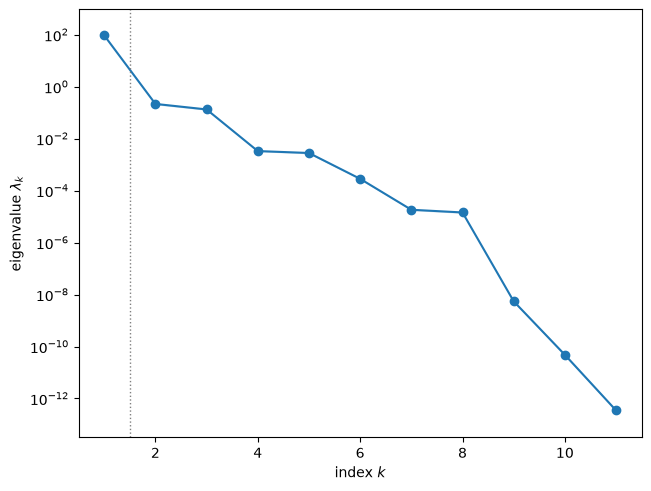

In [8]:
fig, ax = ac.plotting.plot_eigenvalues(subs[0])
plt.close(fig)
fig

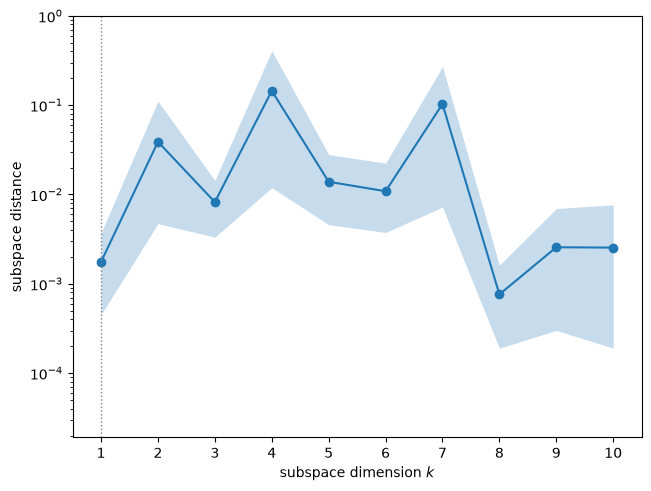

In [9]:
fig, ax = ac.plotting.plot_subspace_errors(subs[0])
plt.close(fig)
fig

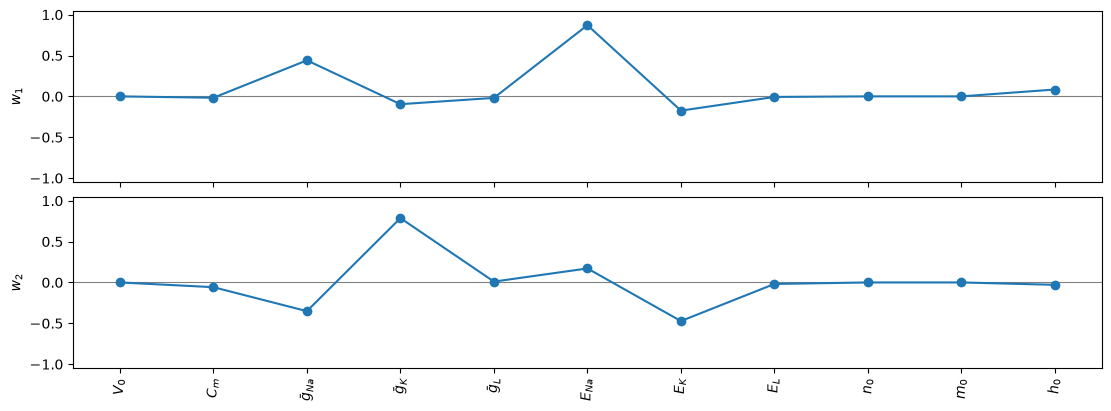

In [10]:
fig, axes = ac.plotting.plot_eigenvectors(subs[0], indices=[0, 1], labels=labels, figsize=(11, 4))
plt.close(fig)
fig

y1 range [-1.49, 1.43]; corr(V_peak, y1) = 0.9987


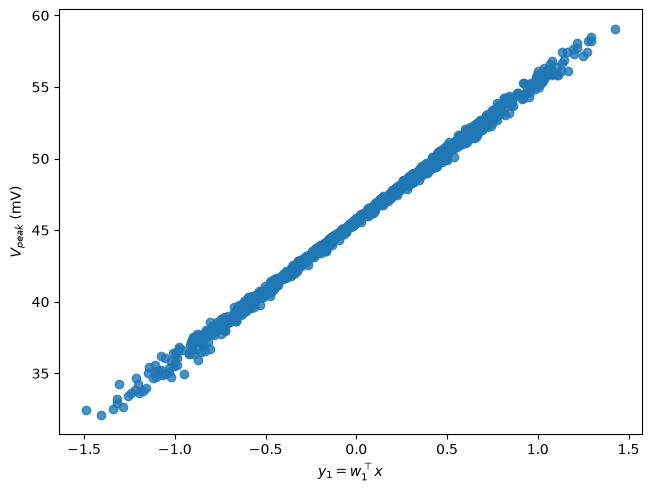

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(subs[0], X=X, f=F[:, 0], dims=1, qoi_label=r'$V_{peak}$ (mV)')
plt.close(fig)
y1 = space.to_normalized(X) @ subs[0].eigenvectors[:, 0]
print(f'y1 range [{y1.min():.2f}, {y1.max():.2f}]; corr(V_peak, y1) = {np.corrcoef(F[:, 0], y1)[0, 1]:.4f}')
fig

$\lambda_1 = 94.61$ mV² (95 % bootstrap band 93.98–95.17) is 434.4 times $\lambda_2$ and holds a share 0.9962 of the trace. $\mathbf w_1$ weights $E_{Na}$ by $+0.871$ and $\bar g_{Na}$ by $+0.441$, then $E_K$ ($-0.174$), $\bar g_K$ ($-0.095$) and $h_0$ ($+0.084$); the leak parameters, $C_m$ and the other initial conditions are below 0.02 in magnitude. The peak rises with the sodium driving force and conductance, the mechanism that sets the peak of an action potential. Against $y_1$ (range $-1.49$ to $1.43$) the peak lies on a thin, nearly straight band (correlation 0.9987). A line in $y_1$ has leave-one-out $R^2 = 0.9975$, a quadratic the same, and a quadratic in $(y_1, y_2)$ 0.9993. The gap $\lambda_1/\lambda_2 = 434.4$, the small subspace distance (0.0018) and the fit all support $n = 1$.

#### Peak time $t_{peak}$

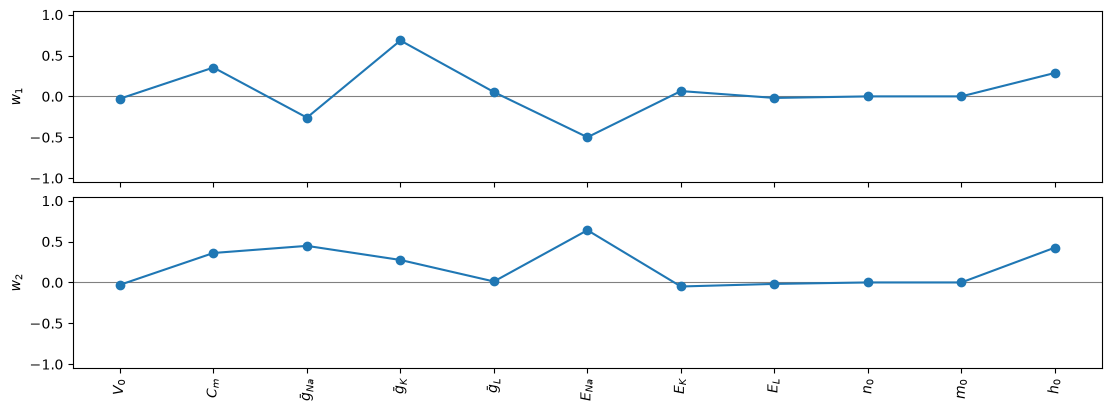

In [12]:
fig, axes = ac.plotting.plot_eigenvectors(subs[1], indices=[0, 1], labels=labels, figsize=(11, 4))
plt.close(fig)
fig

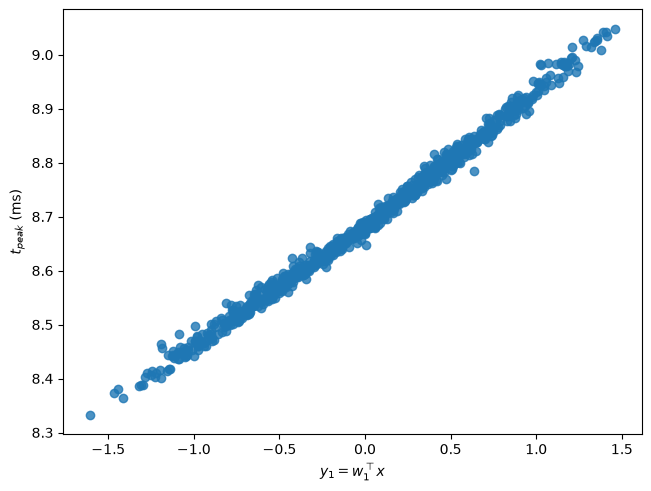

In [13]:
fig, ax = ac.plotting.plot_sufficient_summary(subs[1], X=X, f=F[:, 1], dims=1, qoi_label=r'$t_{peak}$ (ms)')
plt.close(fig)
fig

For $t_{peak}$, $\lambda_1/\lambda_2 = 134.5$ (share of the trace 0.9889; subspace distance 0.0030). $\mathbf w_1$ weights $\bar g_K$ by $+0.684$, $E_{Na}$ by $-0.500$, $C_m$ by $+0.353$, $h_0$ by $+0.287$ and $\bar g_{Na}$ by $-0.260$: the peak comes later with more potassium conductance and a larger capacitance, and earlier with a stronger sodium current. A line in $y_1$ has leave-one-out $R^2 = 0.9925$ and a quadratic 0.9946; a quadratic in two active variables, 0.9962, adds little.

#### The minimum after the peak, $V_{min}$ and $t_{min}$

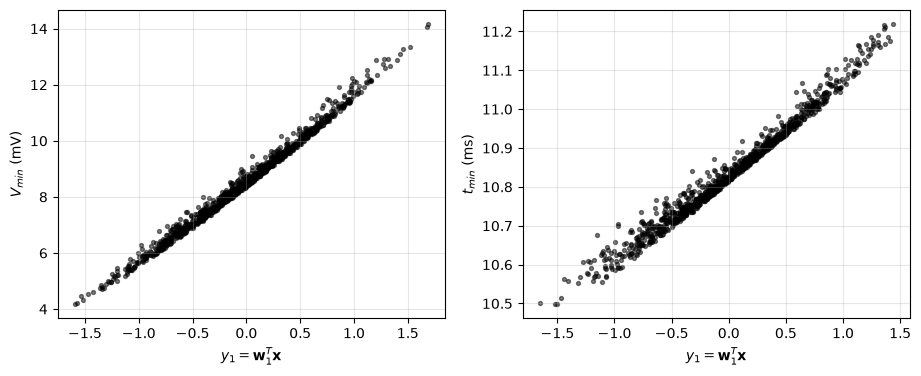

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, q, lab in zip(axes, (2, 3), (r'$V_{min}$ (mV)', r'$t_{min}$ (ms)')):
    yq = space.to_normalized(X) @ subs[q].eigenvectors[:, 0]
    ax.scatter(yq, F[:, q], s=8, c='k', alpha=0.5)
    ax.set_xlabel(r'$y_1 = \mathbf{w}_1^T\mathbf{x}$'); ax.set_ylabel(lab); ax.grid(alpha=0.3)
plt.close(fig)
fig

For $V_{min}$, $\lambda_1/\lambda_2 = 49.9$ and $\lambda_2/\lambda_3 = 14.8$. $\mathbf w_1$ is led by $E_{Na}$ ($-0.715$), $E_K$ ($+0.449$), $\bar g_K$ ($-0.394$) and $\bar g_{Na}$ ($-0.355$), and $\mathbf w_2$ by $\bar g_K$ ($-0.720$). For $t_{min}$, $\lambda_1/\lambda_2 = 35.3$ and $\lambda_2/\lambda_3 = 8.9$, with $\mathbf w_1$ led by $E_{Na}$ ($-0.679$), $C_m$ ($+0.465$), $\bar g_K$ ($+0.351$), $E_K$ ($+0.282$) and $h_0$ ($+0.266$). A quadratic in $y_1$ has leave-one-out $R^2 = 0.9917$ for $V_{min}$ and 0.9820 for $t_{min}$. A quadratic in $(y_1, y_2)$ raises these to 0.9988 and 0.9986, so for the trough a two-dimensional subspace is the better choice when a surrogate is the aim. The visible scatter about the one-dimensional trend in the plots above is the second direction.

### Sensitivity over time

The paper shows first-order Sobol' indices of $V(t)$ at each time ([[1]](https://doi.org/10.3389/fninf.2018.00049), Fig. 4B, p. 20). From the gradients we compute, at each of the 21 times, the diagonal of $\mathbf C$ for $V(t)$, the mean squared derivative $C_{jj}$ along each normalized input, and use it in two ways:

- the *scaled score* $C_{jj}/\max_k C_{kk}$, so that the leading input scores 1, to rank the inputs; we also average it over the 21 times;
- the *share of the trace* $C_{jj}/\operatorname{tr}\mathbf C$, to compare with the values of Fig. 4B. For a function linear in independent inputs uniform on $[-1, 1]$, $f = c + \sum_j a_j x_j$, both $C_{jj}/\operatorname{tr}\mathbf C$ and the first-order Sobol' index equal $a_j^2/\sum_k a_k^2$. For a nonlinear function they need not agree.

time-averaged scaled score: gK 0.673, ENa 0.654, gNa 0.223, h0 0.193, Cm 0.151, EK 0.143, gL 0.002, V0 0.001, EL 0.001, n0 0.000, m0 0.000
leading input at each time: 5 ENa, 5.5 ENa, 6 ENa, 6.5 gK, 7 gK, 7.5 gK, 8 gK, 8.5 ENa, 9 ENa, 9.5 gK, 10 ENa, 10.5 ENa, 11 ENa, 11.5 gK, 12 gK, 12.5 gK, 13 gK, 13.5 gK, 14 gK, 14.5 ENa, 15 ENa
h0 scaled score >= 0.1 at 11 of 21 times, the last at 11.5 ms; after that between 0.012 and 0.094
scaled score of h0 over time: 5: 0.350, 5.5: 0.377, 6: 0.434, 6.5: 0.544, 7: 0.353, 7.5: 0.239, 8: 0.162, 8.5: 0.006, 9: 0.161, 9.5: 0.539, 10: 0.369, 10.5: 0.022, 11: 0.037, 11.5: 0.103, 12: 0.094, 12.5: 0.078, 13: 0.063, 13.5: 0.051, 14: 0.041, 14.5: 0.012, 15: 0.013
share of the trace held by h0 over time: 5: 0.142, 5.5: 0.150, 6: 0.158, 6.5: 0.170, 7: 0.188, 7.5: 0.164, 8: 0.067, 8.5: 0.004, 9: 0.090, 9.5: 0.222, 10: 0.127, 10.5: 0.013, 11: 0.017, 11.5: 0.043, 12: 0.052, 12.5: 0.054, 13: 0.051, 13.5: 0.040, 14: 0.022, 14.5: 0.006, 15: 0.008
h0 share from 10.5

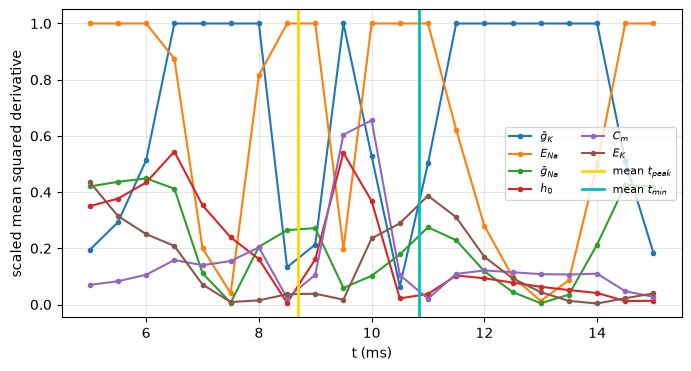

In [15]:
Gn = G[:, 4:, :] * span / 2                       # dV(t)/dx in normalized coordinates, (M, 21, 11)
D = np.mean(Gn ** 2, axis=0)                      # diagonal of C at each time, (21, 11)
S = D / D.max(axis=1, keepdims=True)              # scaled score
share = D / D.sum(axis=1, keepdims=True)          # share of the trace
avg = S.mean(axis=0)
order = np.argsort(-avg)
print('time-averaged scaled score: ' + ', '.join(f'{names[i]} {avg[i]:.3f}' for i in order))
print('leading input at each time: ' + ', '.join(f'{tt:g} {names[int(np.argmax(S[k]))]}' for k, tt in enumerate(hm.TIMES)))
jh = names.index('h0')
THRESHOLD = 0.1                                   # this data set's choice, for counting times
big = hm.TIMES[S[:, jh] >= THRESHOLD]
print(f'h0 scaled score >= {THRESHOLD} at {len(big)} of {len(hm.TIMES)} times, the last at {big.max():g} ms; '
      f'after that between {S[hm.TIMES > big.max(), jh].min():.3f} and {S[hm.TIMES > big.max(), jh].max():.3f}')
print('scaled score of h0 over time: ' + ', '.join(f'{tt:g}: {S[k, jh]:.3f}' for k, tt in enumerate(hm.TIMES)))
print('share of the trace held by h0 over time: ' + ', '.join(f'{tt:g}: {share[k, jh]:.3f}' for k, tt in enumerate(hm.TIMES)))
late = hm.TIMES >= 10.5
print(f'h0 share from 10.5 ms on: at most {share[late, jh].max():.3f}')
print(f"largest scaled score over the window: V0 {S[:, names.index('V0')].max():.1e}, "
      f"n0 {S[:, names.index('n0')].max():.1e}, m0 {S[:, names.index('m0')].max():.1e}, "
      f"gL {S[:, names.index('gL')].max():.1e}, EL {S[:, names.index('EL')].max():.1e}")
fig, ax = plt.subplots(figsize=(8, 4))
for j in order[:6]:
    ax.plot(hm.TIMES, S[:, j], '.-', label=labels[j])
ax.axvline(F[:, 1].mean(), color='gold', lw=2, label=r'mean $t_{peak}$')
ax.axvline(F[:, 3].mean(), color='c', lw=2, label=r'mean $t_{min}$')
ax.set_xlabel('t (ms)'); ax.set_ylabel('scaled mean squared derivative'); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.close(fig)
fig

Averaged over the window, the two leading inputs are $\bar g_K$ (0.673) and $E_{Na}$ (0.654), well ahead of $\bar g_{Na}$ (0.223), $h_0$ (0.193), $C_m$ (0.151) and $E_K$ (0.143). The paper finds the same two inputs from first-order Sobol' indices ([[1]](https://doi.org/10.3389/fninf.2018.00049), §4.2, p. 19, and Fig. 4B, p. 20). The leading input changes along the action potential:
- $\bar g_K$ during the upstroke (6.5–8 ms);
- $E_{Na}$ at the peak (8.5–9 ms);
- $\bar g_K$ on the downstroke (9.5 ms);
- $E_{Na}$ again in the window after the peak (10–11 ms);
- $\bar g_K$ from 11.5 to 14 ms.

The paper describes the same sequence (§4.2, p. 19): $\bar g_K$ for the upstroke, $E_{Na}$ for the peak, $\bar g_K$ for the downstroke, and $E_{Na}$ in "a time window after the peak". $V_0$, $n_0$, $m_0$, $\bar g_L$ and $E_L$ have scaled scores of at most $1.1\times10^{-2}$ anywhere in the window. The paper also finds $V_0$, $m_0$ and $n_0$ negligible, and a low sensitivity to the leak parameters under this stimulus. The paper says the model "maintains a sensitivity to the initial Na+ inactivation state ($h_0$) through most of the simulation" (§4.2, p. 19). Here the share of the trace held by $h_0$ is between 0.127 and 0.222 at 8 of the 11 times up to 10 ms. It is lower around the peak: 0.067 at 8 ms, 0.004 at 8.5 ms and 0.090 at 9 ms. From 10.5 ms on it is at most 0.054. The scaled score shows the same pattern: with a threshold of 0.1, which is our choice, $h_0$ reaches it at 11 of the 21 times, the last at 11.5 ms, and stays between 0.012 and 0.094 after that. Fig. 4B of the paper shows the same shape for the Sobol' index of $h_0$ (approximate read-offs, compared in the next section): about 0.14–0.19 from 5 to 7.5 ms, near 0 at the peak, about 0.23 near 9.5 ms, near 0 again around 10.5 ms, then about 0.02 at 11 ms, 0.03–0.05 from 11.5 to 13.5 ms and at most about 0.02 from 14 ms on. So $h_0$ is moderate up to about 10 ms and small after it, both here and in Fig. 4B. The paper's "through most of the simulation" describes a longer persistence than either shows.

### Comparison with the paper

The paper gives its time-resolved results as figures and statements; it prints no numerical Sobol' indices. Its Fig. 4 ([[1]](https://doi.org/10.3389/fninf.2018.00049), p. 20) has labeled axes, and the values below are our approximate read-offs of it, measured on the published figure against its axis labels. In Fig. 4B only the $E_{Na}$ panel has tick labels; we assume that every panel shares its 0–1 axis, as the identical panel sizes suggest. Where an index curve runs along the axis, the axis hides the lower half of the line, so we read the index from the line's upper edge. We estimate the read-offs good to about 0.05 ms in time, 0.5 mV for the mean, 0.1 mV for the standard deviation and 0.02 for an index. The paper's numbers come from a polynomial chaos expansion, ours from 1000 Monte Carlo samples (the mean and standard deviation from the 0.01 ms grid above, the index from the share of the trace).

In [16]:
# Approximate read-offs of Fig. 4 of [1], p. 20: (quantity, read-off, this data set)
t_sd, v_sd = extremum(sd, 5, 15)
t_sd2, v_sd2 = extremum(sd, 9.5, 11)
t_sd3, v_sd3 = extremum(sd, 12, 15)
t_mx, v_mx = extremum(mu, 7, 10)
t_mn, v_mn = extremum(mu, 9.5, 12, largest=False)
k_t = {tt: k for k, tt in enumerate(hm.TIMES)}
rows = [('Fig. 4A, largest standard deviation (mV)', 6.1, v_sd), ('  its time (ms)', 8.45, t_sd),
        ('Fig. 4A, standard deviation maximum on the downstroke (mV)', 2.6, v_sd2), ('  its time (ms)', 10.1, t_sd2),
        ('Fig. 4A, standard deviation maximum near the end (mV)', 5.0, v_sd3), ('  its time (ms)', 14.6, t_sd3),
        ('Fig. 4A, peak of the mean (mV)', 45.0, v_mx), ('  its time (ms)', 8.65, t_mx),
        ('Fig. 4A, minimum of the mean (mV)', 8.8, v_mn), ('  its time (ms)', 10.86, t_mn),
        ('Fig. 4A, mean at 15 ms (mV)', 34.0, mu[-1]),
        ('yellow line, peak (ms) vs nominal t_peak', 8.67, f_nom[1]),
        ('  vs mean of t_peak over the samples', 8.67, F[:, 1].mean()), ('  vs peak of the mean', 8.67, t_mx),
        ('cyan line, minimum (ms) vs nominal t_min', 10.85, f_nom[3]),
        ('  vs mean of t_min over the samples', 10.85, F[:, 3].mean()), ('  vs minimum of the mean', 10.85, t_mn)]
rows += [(f'Fig. 4B, Sobol index of h0 at {tt:g} ms vs share of the trace', r, share[k_t[tt], jh])
         for tt, r in ((6.0, 0.16), (7.0, 0.18), (9.5, 0.23), (12.0, 0.05), (13.0, 0.05))]
print(f"{'quantity':62s} {'read-off':>9s} {'here':>9s} {'here - read-off':>16s}")
for q, r, h in rows:
    print(f'{q:62s} {r:9g} {h:9.3f} {h - r:+16.3f}')

quantity                                                        read-off      here  here - read-off
Fig. 4A, largest standard deviation (mV)                             6.1     6.101           +0.001
  its time (ms)                                                     8.45     8.450           +0.000
Fig. 4A, standard deviation maximum on the downstroke (mV)           2.6     2.612           +0.012
  its time (ms)                                                     10.1    10.150           +0.050
Fig. 4A, standard deviation maximum near the end (mV)                  5     5.012           +0.012
  its time (ms)                                                     14.6    14.640           +0.040
Fig. 4A, peak of the mean (mV)                                        45    45.314           +0.314
  its time (ms)                                                     8.65     8.660           +0.010
Fig. 4A, minimum of the mean (mV)                                    8.8     8.648           -0.152


Every feature of Fig. 4A that we read is reproduced to within the read-off precision. The largest difference is 0.31 mV, in the peak of the mean. The standard deviation has its three maxima at the same places and heights, and the mean has its peak, minimum and end value where the figure has them. The yellow and cyan lines fall within 0.04 ms of the nominal peak and minimum times, of the means of $t_{peak}$ and $t_{min}$ over the samples, and of the extrema of the mean. The read-off cannot tell which of these the paper marks. The index of $h_0$ in Fig. 4B and its share of the trace here agree to within 0.01 at the five times read.

| Paper ([[1]](https://doi.org/10.3389/fninf.2018.00049), §4.2, pp. 18–19, and Fig. 4, p. 20) | This notebook |
|---|---|
| Inputs: 11 parameters, Table 2, each uniform within ±10 % | the same 11 inputs and ranges |
| Stimulus 140 μA/cm² from $t = 0$; window 5–15 ms; rest at 0 mV | the same; end time 15 ms, solver and outputs are our choices |
| Upstroke and peak "between t = 8 and 9 ms" | nominal peak at 8.681 ms; $t_{peak}$ in 8.333–9.048 ms over the samples |
| Variance of $V$ largest during the upstroke and peak; read-off about 6.1 mV at about 8.45 ms | largest standard deviation 6.10 mV at 8.45 ms |
| Mean, standard deviation and marker lines of Fig. 4A (read-offs above) | all within the read-off precision (table above) |
| Variance mainly due to $\bar g_K$ and $E_{Na}$ | time-averaged scaled scores $\bar g_K$ 0.673, $E_{Na}$ 0.654; next $\bar g_{Na}$ 0.223 |
| Peak potential most sensitive to $E_{Na}$ | $E_{Na}$ leads at 8.5 and 9 ms; $V_{peak}$ has $w_{1,E_{Na}} = +0.871$ |
| Upstroke most sensitive to $\bar g_K$; $\bar g_K$ most important on the downstroke | $\bar g_K$ leads at 6.5–8 ms and at 9.5 ms |
| $E_{Na}$ sensitive in a window after the peak | $E_{Na}$ leads at 10–11 ms |
| Negligible sensitivity to $V_0$, $m_0$, $n_0$ | largest scaled scores $3.7\times10^{-3}$, $7.4\times10^{-10}$, $6.3\times10^{-8}$ |
| Sensitivity to $h_0$ "through most of the simulation"; in Fig. 4B, moderate up to about 10 ms and at most about 0.05 from 11 ms on | share of the trace moderate up to 10 ms, at most 0.054 from 10.5 ms on: **agrees with Fig. 4B; the paper's sentence is broader than either** |

Two of the paper's values differ from the corresponding values of Torres Valderrama et al. [[3]](https://doi.org/10.1186/2190-8567-5-3) (Table 2 there), the study it repeats. The paper's Table 2 (p. 19) has $E_{Na} = 112$ mV, $n_0 = 0.0011$ and $m_0 = 0.0003$; the earlier table has $E_{Na} = 115$ mV and the two initial values exchanged ($n_0 = 0.0003$, $m_0 = 0.0011$). The Uncertainpy example code [[4]](https://github.com/simetenn/uncertainpy/tree/ffb2400289743066265b9a8561cdf3b72e478a28/examples/valderrama) uses 112 mV and the exchanged initial values. We use the paper's Table 2 as printed. `check_accuracy.py` (check 4) shows that exchanging $m_0$ and $n_0$ changes $V(t)$ by at most 0.007 mV. With $E_{Na} = 115$ mV the nominal peak would be 48.13 mV instead of 45.87 mV.

### References

[1] S. Tennøe, G. Halnes and G. T. Einevoll. Uncertainpy: a Python toolbox for uncertainty quantification and sensitivity analysis in computational neuroscience. *Frontiers in Neuroinformatics* 12:49, 2018. [doi:10.3389/fninf.2018.00049](https://doi.org/10.3389/fninf.2018.00049). Open access, CC BY 4.0. Page numbers refer to the published PDF.

[2] A. L. Hodgkin and A. F. Huxley. A quantitative description of membrane current and its application to conduction and excitation in nerve. *The Journal of Physiology* 117(4):500–544, 1952. [doi:10.1113/jphysiol.1952.sp004764](https://doi.org/10.1113/jphysiol.1952.sp004764).

[3] A. Torres Valderrama, J. Witteveen, M. Navarro and J. Blom. Uncertainty propagation in nerve impulses through the action potential mechanism. *The Journal of Mathematical Neuroscience* 5:3, 2015. [doi:10.1186/2190-8567-5-3](https://doi.org/10.1186/2190-8567-5-3). Source of the rate functions (Eq. 1).

[4] Uncertainpy, GitHub repository simetenn/uncertainpy, example `examples/valderrama/` at commit [ffb2400](https://github.com/simetenn/uncertainpy/tree/ffb2400289743066265b9a8561cdf3b72e478a28/examples/valderrama) (GPL-3.0; read for its settings, not copied).

[5] active_subspaces, version 1, at the commit pinned in `requirements.txt`: [github.com/paulcon/active_subspaces](https://github.com/paulcon/active_subspaces).

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 36.3 s
